# 03. Mô hình cây: Decision Tree, Random Forest, Gradient Boosting

**Mục tiêu học:** thấy tận mắt overfitting của cây đơn, sức mạnh của ensemble, và vì sao Gradient Boosting mặc định có thể **kém bất thường** (underfitting) nếu không chỉnh số cây.

**Liên hệ lý thuyết:** `DecisionTree.ipynb` và `EnsembleMethods.ipynb` (thư mục MACHINE_LEARNING).

**Nội dung**
1. Chuẩn bị dữ liệu cho mô hình cây
2. Cây đơn: độ sâu và overfitting
3. Random Forest: số cây, `min_samples_leaf`, `max_features`
4. Tác động của log(giá) lên mô hình cây
5. Gradient Boosting: vì sao bản mặc định kém?
6. So sánh các mô hình
7. Tổng kết

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score

from used_car_price.config import FEATURES, CATEGORICAL, NUMERIC, TARGET, RANDOM_STATE, RAW_PATH, TEST_SIZE
from used_car_price.data import load_data
from used_car_price.features import build_preprocessor
from used_car_price.train import log_target
from used_car_price.metrics import evaluate

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (7, 4.2)

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_percentage_error as mape

## 1. Chuẩn bị dữ liệu cho mô hình cây

Cây không cần chuẩn hoá số, nhưng với `sklearn` ta vẫn cần one-hot cho cột chữ. Để vẽ đường học nhanh, ta biến đổi dữ liệu một lần (an toàn vì bộ biến đổi chỉ `fit` trên tập train).

In [2]:
df = load_data(); X, y = df[FEATURES], df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
prep = build_preprocessor(scale_numeric=False).fit(X_tr)          # fit chỉ trên train
A_tr, A_te = prep.transform(X_tr).toarray(), prep.transform(X_te).toarray()
ly_tr = np.log1p(y_tr)                                              # huấn luyện trên log giá
print("Ma trận đặc trưng:", A_tr.shape, "(nhiều cột do one-hot dòng xe, hãng, tỉnh...)")

def test_mape(model_log):                                           # đánh giá trên thang giá gốc
    return mape(y_te, np.expm1(model_log.predict(A_te)))

Ma trận đặc trưng: (2279, 158) (nhiều cột do one-hot dòng xe, hãng, tỉnh...)


## 2. Cây đơn: độ sâu và overfitting

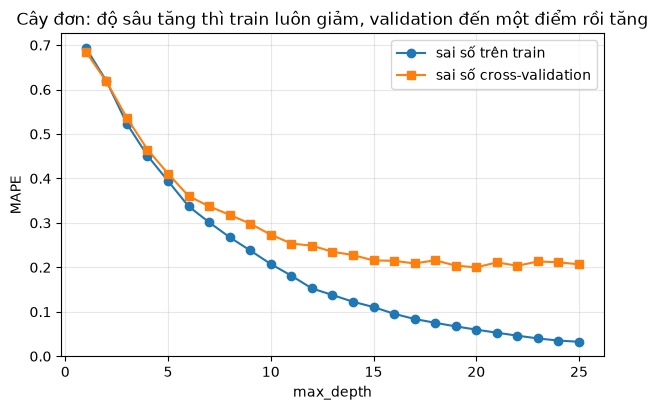

max_depth tốt nhất theo CV: 20 | MAPE CV = 20.0%


In [3]:
depths = list(range(1, 26)); tr_e, va_e = [], []
from sklearn.model_selection import cross_val_predict
for d_ in depths:
    m = DecisionTreeRegressor(max_depth=d_, random_state=0).fit(A_tr, ly_tr)
    tr_e.append(mape(y_tr, np.expm1(m.predict(A_tr))))
    va_e.append(mape(y_tr, np.expm1(cross_val_predict(DecisionTreeRegressor(max_depth=d_, random_state=0), A_tr, ly_tr, cv=5))))
plt.plot(depths, tr_e, "o-", label="sai số trên train"); plt.plot(depths, va_e, "s-", label="sai số cross-validation")
plt.xlabel("max_depth"); plt.ylabel("MAPE"); plt.legend(); plt.grid(alpha=.3); plt.title("Cây đơn: độ sâu tăng thì train luôn giảm, validation đến một điểm rồi tăng")
plt.show()
best_d = depths[int(np.argmin(va_e))]; print("max_depth tốt nhất theo CV:", best_d, f"| MAPE CV = {min(va_e):.1%}")

**Đọc biểu đồ:** sai số train giảm về gần 0 khi cây sâu hơn (cây học thuộc dữ liệu), còn sai số validation giảm rồi **đi ngang** ở mức cao hơn nhiều. Dấu hiệu overfitting là **khoảng cách lớn giữa hai đường** (phương sai cao), không nhất thiết là validation tăng trở lại. Ở đây validation không tăng vì cây sâu hơn chỉ chia nhỏ thêm các lá đã gần thuần nhất.

In [4]:
from sklearn.tree import export_text
small = DecisionTreeRegressor(max_depth=3, min_samples_leaf=30, random_state=0).fit(A_tr, ly_tr)
print(export_text(small, feature_names=list(prep.get_feature_names_out()), max_depth=3)[:2500])

|--- cat__origin_trong nước <= 0.50
|   |--- cat__brand_Lexus <= 0.50
|   |   |--- cat__brand_Porsche <= 0.50
|   |   |   |--- value: [6.78]
|   |   |--- cat__brand_Porsche >  0.50
|   |   |   |--- value: [7.95]
|   |--- cat__brand_Lexus >  0.50
|   |   |--- cat__model_LX <= 0.50
|   |   |   |--- value: [7.62]
|   |   |--- cat__model_LX >  0.50
|   |   |   |--- value: [8.32]
|--- cat__origin_trong nước >  0.50
|   |--- cat__brand_Mercedes Benz <= 0.50
|   |   |--- num__age <= 6.50
|   |   |   |--- value: [6.50]
|   |   |--- num__age >  6.50
|   |   |   |--- value: [5.85]
|   |--- cat__brand_Mercedes Benz >  0.50
|   |   |--- num__age <= 7.50
|   |   |   |--- value: [7.26]
|   |   |--- num__age >  7.50
|   |   |   |--- value: [6.50]



Cây nông này cho thấy các câu hỏi quan trọng nhất (xuất xứ, hãng sang như Lexus/Porsche/Mercedes, rồi tuổi xe). `value` là **log1p(giá)** trung bình trong lá (vd. 6,5 tương ứng khoảng 665 triệu). Cây đơn **dễ giải thích** nhưng không chính xác bằng ensemble.

## 3. Random Forest

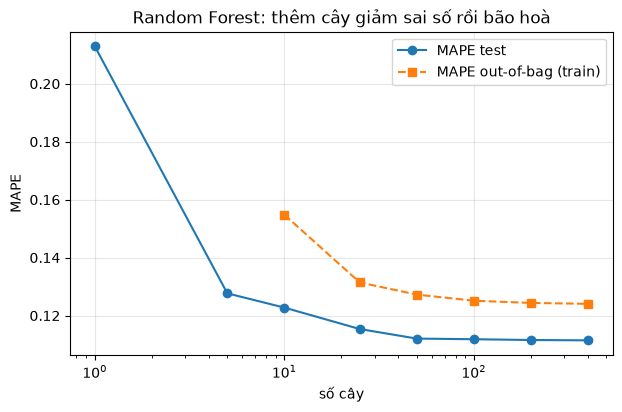

In [5]:
ns = [1, 5, 10, 25, 50, 100, 200, 400]; oob, tst = [], []
for n_ in ns:
    rf = RandomForestRegressor(n_estimators=n_, oob_score=(n_ >= 10), random_state=0, n_jobs=-1).fit(A_tr, ly_tr)
    tst.append(test_mape(rf)); oob.append(mape(y_tr, np.expm1(rf.oob_prediction_)) if n_ >= 10 else np.nan)
plt.semilogx(ns, tst, "o-", label="MAPE test"); plt.semilogx(ns, oob, "s--", label="MAPE out-of-bag (train)")
plt.xlabel("số cây"); plt.ylabel("MAPE"); plt.legend(); plt.grid(alpha=.3); plt.title("Random Forest: thêm cây giảm sai số rồi bão hoà"); plt.show()

Thêm cây **không gây overfit** (khác với tăng độ sâu của một cây); sai số bão hoà. **OOB** (out-of-bag) cho ước lượng sai số mà không cần tập validation riêng.

Bây giờ thử hai siêu tham số khác: `min_samples_leaf` (độ mịn của lá) và `max_features` (số cột xét mỗi lần chia).

In [6]:
rows = []
for leaf in [1, 2, 5, 10, 20]:
    for mf in [0.2, 0.5, 1.0]:
        rf = RandomForestRegressor(200, min_samples_leaf=leaf, max_features=mf, random_state=0, n_jobs=-1).fit(A_tr, ly_tr)
        rows.append({"min_samples_leaf": leaf, "max_features": mf, "MAPE test": test_mape(rf)})
g = pd.DataFrame(rows).pivot(index="min_samples_leaf", columns="max_features", values="MAPE test")
display((g * 100).round(2).style.background_gradient(cmap="viridis_r").format("{:.2f}%"))

max_features,0.200000,0.500000,1.000000
min_samples_leaf,,,
1,12.70%,11.33%,11.16%
2,16.30%,13.14%,12.54%
5,23.32%,19.61%,18.09%
10,30.26%,26.70%,25.61%
20,40.08%,35.43%,34.73%


**Hỏi:** vì sao `max_features` nhỏ hơn 1 đôi khi tốt hơn (các cây ít tương quan hơn)? Vì sao `min_samples_leaf` lớn có thể giúp ở dữ liệu nhiễu như giá rao bán?

## 4. Tác động của log(giá) lên mô hình cây

Cây dự đoán trung bình trong lá. Trên giá thô, trung bình bị chi phối bởi xe đắt; trên log, nó là trung bình nhân (ổn định theo %).

In [7]:
rf_raw = RandomForestRegressor(300, random_state=0, n_jobs=-1).fit(A_tr, y_tr)
rf_log = RandomForestRegressor(300, random_state=0, n_jobs=-1).fit(A_tr, ly_tr)
display(pd.DataFrame({"giá thô": evaluate(y_te, rf_raw.predict(A_te)), "log(giá)": evaluate(y_te, np.expm1(rf_log.predict(A_te)))}).T.round(3))

,MAPE,sai_so_%_trung_vi,MAE,RMSE,R2
giá thô,0.126,0.068,123.392,281.719,0.949
log(giá),0.112,0.069,130.074,318.988,0.934


**Quan sát:** log(giá) cho **MAPE** tốt hơn (sai số % thấp hơn) nhưng có thể kém hơn ở **RMSE/R²** (các độ đo này do xe sang chi phối). Không có mô hình "tốt nhất" tuyệt đối: nó phụ thuộc vào độ đo bạn quan tâm. Với người dùng cuối thì sai số % thường là thước đo tự nhiên hơn.

## 5. Gradient Boosting: vì sao bản mặc định kém?

Boosting thêm từng cây nhỏ để sửa lỗi của tổng các cây trước, nhân với `learning_rate`. Với 100 cây và `learning_rate=0.1`, mô hình chỉ "đi" được một đoạn hữu hạn về phía đích: **chưa hội tụ (underfit)**. Hãy xem sai số theo số cây.

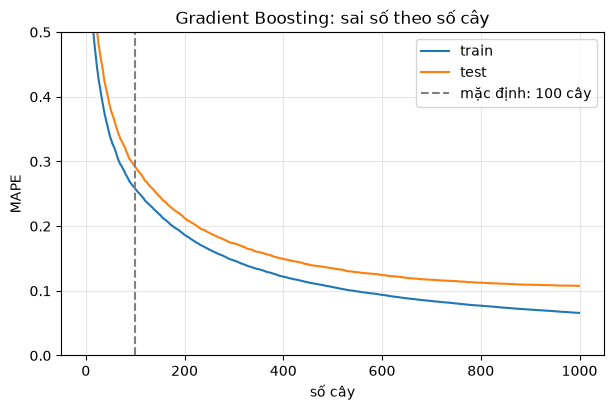

MAPE test tại 100 cây: 29.2% | tại 1000 cây: 10.8% | tốt nhất: 10.8% (cây thứ 998)


In [8]:
gb = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=0).fit(A_tr, ly_tr)
tr_curve = [mape(y_tr, np.expm1(p)) for p in gb.staged_predict(A_tr)]
te_curve = [mape(y_te, np.expm1(p)) for p in gb.staged_predict(A_te)]
plt.plot(tr_curve, label="train"); plt.plot(te_curve, label="test"); plt.axvline(100, c="gray", ls="--", label="mặc định: 100 cây")
plt.ylim(0, 0.5); plt.xlabel("số cây"); plt.ylabel("MAPE"); plt.legend(); plt.grid(alpha=.3); plt.title("Gradient Boosting: sai số theo số cây"); plt.show()
print(f"MAPE test tại 100 cây: {te_curve[99]:.1%} | tại 1000 cây: {te_curve[-1]:.1%} | tốt nhất: {min(te_curve):.1%} (cây thứ {int(np.argmin(te_curve)) + 1})")

**Bài học:** đường test còn đang **đi xuống** ở 100 cây, tức mô hình mặc định chưa học xong. Đây là lỗi thường gặp: kết luận "Gradient Boosting kém hơn Random Forest" chỉ vì dùng tham số mặc định. Trong `src/used_car_price/train.py` ta dùng 800 cây, `learning_rate=0.05`.

Tương tác giữa `learning_rate` và số cây:

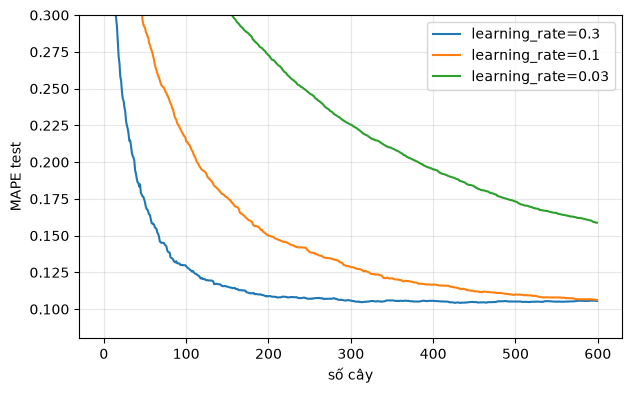

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for lr_ in [0.3, 0.1, 0.03]:
    g_ = GradientBoostingRegressor(n_estimators=600, learning_rate=lr_, max_depth=4, subsample=0.8, random_state=0).fit(A_tr, ly_tr)
    ax.plot([mape(y_te, np.expm1(p)) for p in g_.staged_predict(A_te)], label=f"learning_rate={lr_}")
ax.set_ylim(0.08, 0.3); ax.set_xlabel("số cây"); ax.set_ylabel("MAPE test"); ax.legend(); ax.grid(alpha=.3); plt.show()

`learning_rate` lớn học nhanh nhưng dễ dao động và overfit; nhỏ thì cần nhiều cây hơn nhưng thường tốt hơn. Biến thể nhanh: `HistGradientBoostingRegressor` (ghép nhóm giá trị, hỗ trợ cột phân loại trực tiếp).

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
pre_h = ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL)], remainder="passthrough").fit(X_tr)
hgb = HistGradientBoostingRegressor(categorical_features=list(range(len(CATEGORICAL))), max_iter=500, learning_rate=0.05, random_state=0).fit(pre_h.transform(X_tr), ly_tr)
print(f"HistGradientBoosting (cột phân loại gốc, không one-hot): MAPE test = {mape(y_te, np.expm1(hgb.predict(pre_h.transform(X_te)))):.1%}")

HistGradientBoosting (cột phân loại gốc, không one-hot): MAPE test = 13.4%


## 6. So sánh các mô hình (cross-validation đầy đủ)

In [11]:
from used_car_price.train import candidates
res = {}
for name, pipe in candidates().items():
    s = -cross_val_score(pipe, X_tr, y_tr, cv=5, scoring="neg_mean_absolute_percentage_error")
    res[name] = (s.mean(), s.std())
out = pd.DataFrame(res, index=["MAPE trung bình", "độ lệch chuẩn"]).T.sort_values("MAPE trung bình")
display((out * 100).round(2))

,MAPE trung bình,độ lệch chuẩn
random_forest,13.69,1.12
gradient_boosting,13.73,1.54
linear_regression (baseline),17.33,1.37
ridge,17.53,1.23


## 7. Tổng kết

- **Cây đơn:** dễ giải thích, nhưng overfit khi sâu; cần giới hạn `max_depth`/`min_samples_leaf`.
- **Random Forest:** mạnh ngay với tham số mặc định, ít nhạy, có OOB; thêm cây không gây overfit.
- **Gradient Boosting:** thường tốt nhất khi **chỉnh đúng** số cây và `learning_rate`; bản mặc định dễ underfit.
- Mô hình cây bắt được tương tác và phi tuyến mà mô hình tuyến tính bỏ lỡ.

## Bài tập
1. Vẽ đường cong học (`learning_curve`) của Random Forest: thêm dữ liệu có giúp không?
2. Dùng `max_depth` của GB là 2, 4, 6, 8. Độ sâu nào tốt nhất? Giải thích bằng bias-variance.
3. Thử `subsample` từ 0,5 đến 1,0. Tác dụng của nó là gì?
4. Thử `ExtraTreesRegressor`. So với Random Forest ra sao?
5. Với `HistGradientBoostingRegressor`, thử bật `early_stopping=True` và quan sát số vòng lặp dừng.